In [1]:
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.linear_model import (LinearRegression, Ridge, Lasso, RidgeCV, LassoCV,
                                  ElasticNet, ElasticNetCV)
from sklearn.model_selection import (StratifiedKFold, KFold, 
                                     cross_val_score, learning_curve,
                                     GridSearchCV)
from sklearn.preprocessing import PolynomialFeatures

In [2]:
plt.rcParams['font.size'] = 14

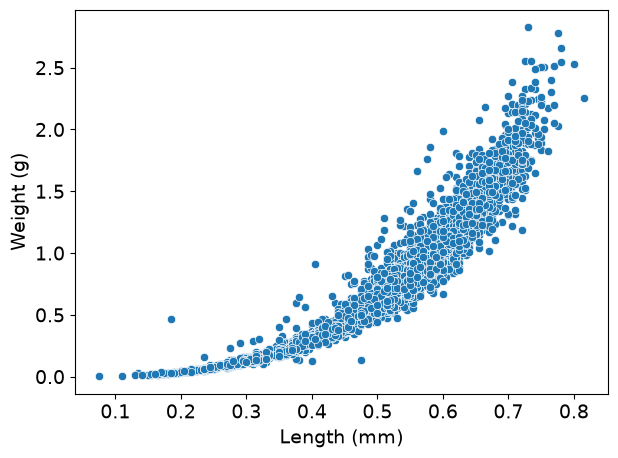

In [3]:
data = pd.read_csv('abalone.data', header=None)
data
X = data.iloc[:,1:2].to_numpy() # Length (mm)
y = data.iloc[:, 4].to_numpy() # Weight (g)
X = PolynomialFeatures(degree=1, include_bias=False).fit_transform(X)
sns.scatterplot(x=X[:,0], y=y)
plt.xlabel('Length (mm)')
plt.ylabel('Weight (g)')
plt.tight_layout()

In [4]:
model = LinearRegression()

In [5]:
r2 = cross_val_score(estimator=model, X=X, y=y, cv=10, scoring='r2')
r2

array([0.83878427, 0.83880786, 0.85677619, 0.80748825, 0.84541977,
       0.85592166, 0.84834651, 0.86404638, 0.8691674 , 0.85286473])

In [6]:
r2.mean()

np.float64(0.8477623014543518)

In [7]:
neg_mape = cross_val_score(estimator=model, X=X, y=y, cv=10, 
                           scoring='neg_mean_absolute_percentage_error')
neg_mape

array([-2.04389515, -1.07023421, -0.46399252, -0.36413482, -0.41006672,
       -0.89489903, -0.38134603, -0.39882573, -0.44347607, -0.53300785])

In [8]:
abs(neg_mape.mean())

np.float64(0.7003878122227334)

In [9]:
alpha_range = np.arange(0.01, 10, 10)
param_grid = [
    {'alpha': alpha_range,
    'solver': ['sag', 'saga', 'lsqr']}
]
model = Ridge()
grid_cv = GridSearchCV(estimator=model, param_grid=param_grid, 
             scoring='neg_root_mean_squared_error', refit=True)
grid_cv.fit(X, y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Ridge()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'alpha': array([0.01]), 'solver': ['sag', 'saga', ...]}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the verbosity of informa

In [10]:
grid_cv.best_estimator_.alpha

np.float64(0.01)

In [11]:
alpha = grid_cv.best_estimator_.alpha
solver = grid_cv.best_estimator_.solver
cross_val_score(estimator=Ridge(alpha=alpha, solver=solver), 
                X=X, y=y, 
                scoring='neg_root_mean_squared_error').mean()

np.float64(-0.18710128304638857)

In [12]:
cross_val_score(estimator=Ridge(), X=X, y=y, 
                scoring='neg_root_mean_squared_error').mean()

np.float64(-0.18714132017546453)

In [13]:
model_cv = RidgeCV(alphas=alpha_range, 
                   scoring='neg_root_mean_squared_error', cv=10).fit(X, y)

cross_val_score(estimator=model_cv, X=X, y=y, 
                scoring='neg_root_mean_squared_error').mean()

np.float64(-0.18709736897041987)